In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ntpath
from tqdm import tqdm
from sklearn.neighbors import BallTree

# Wczytanie danych

data = np.loadtxt("wraki-utm.txt")
print(dane)

[[ 4.5261542e+05  5.9678155e+06 -6.7200000e+00]
 [ 4.5261523e+05  5.9678155e+06 -6.6700000e+00]
 [ 4.5261505e+05  5.9678156e+06 -6.6100000e+00]
 ...
 [ 4.5262134e+05  5.9677504e+06 -5.3600000e+00]
 [ 4.5262126e+05  5.9677504e+06 -5.2900000e+00]
 [ 4.5262107e+05  5.9677503e+06 -5.3100000e+00]]


In [42]:
# Pobranie danych od uzytkownika
grid = float(input(f'Określ rozdzielczość grid: '))
print(grid)
radius_window = float(input(f'Określ rozmiar okienka (promień okręgu): '))
print(radius_window)
min_points = float(input(f'Określ minimalną liczbe punktów niezbędnych do wyliczenia nowego punktu: '))
print(min_points)
# grid = 0.2
# radius = 0.4
# minPoints = 3

Określ rozdzielczość grid: 0.2
0.2
Określ rozmiar okienka (promień okręgu): 0.4
0.4
Określ minimalną liczbe punktów niezbędnych do wyliczenia nowego punktu: 3
3.0


In [43]:
# Stworzenie siatki
def create_grid(data, resolution):
    min_values = data.min(axis=0)
    max_values = data.max(axis=0)
    x = np.arange(min_values[0], max_values[0], resolution)
    y = np.arange(min_values[1], max_values[1], resolution)
    return np.meshgrid(x, y)

In [44]:
xMeshGrid, yMeshGrid = create_grid(data, grid)
print(f'{xMeshGrid}\n')
print(f'{yMeshGrid}\n')

[[452606.36 452606.56 452606.76 ... 452631.16 452631.36 452631.56]
 [452606.36 452606.56 452606.76 ... 452631.16 452631.36 452631.56]
 [452606.36 452606.56 452606.76 ... 452631.16 452631.36 452631.56]
 ...
 [452606.36 452606.56 452606.76 ... 452631.16 452631.36 452631.56]
 [452606.36 452606.56 452606.76 ... 452631.16 452631.36 452631.56]
 [452606.36 452606.56 452606.76 ... 452631.16 452631.36 452631.56]]

[[5967748.7        5967748.7        5967748.7        ... 5967748.7
  5967748.7        5967748.7       ]
 [5967748.9        5967748.9        5967748.9        ... 5967748.9
  5967748.9        5967748.9       ]
 [5967749.1        5967749.1        5967749.1        ... 5967749.1
  5967749.1        5967749.1       ]
 ...
 [5967818.90000007 5967818.90000007 5967818.90000007 ... 5967818.90000007
  5967818.90000007 5967818.90000007]
 [5967819.10000007 5967819.10000007 5967819.10000007 ... 5967819.10000007
  5967819.10000007 5967819.10000007]
 [5967819.30000007 5967819.30000007 5967819.30000007

In [45]:
# Interpolacja metodą Moving Average
def interp_mov_avg(data, xMesh, yMesh, min_points, radius_window):
    ballTree = BallTree(data[:, :2])
    zMesh = np.empty((xMeshGrid.shape[0], xMeshGrid.shape[1]))

    for i in tqdm(range(xMesh.shape[0]), desc='Loading...'):
        for j in range(xMesh.shape[1]):
            # query the tree for neighbours within radius r
            idx = ballTree.query_radius([[xMesh[i, j], yMesh[i, j]]], r=radius_window)

            if len(idx[0]) < min_points:
                zMesh[i, j] = np.NaN
            else:
                zMesh[i, j] = np.mean(data[idx[0], 2])
    return zMesh

In [46]:
zMeshGrid = interp_mov_avg(data, xMeshGrid, yMeshGrid, minPoints, radius)
print(f'{zMeshGrid}\n')

Loading...: 100%|██████████| 354/354 [00:06<00:00, 58.27it/s]

[[nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 ...
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]
 [nan nan nan ... nan nan nan]]



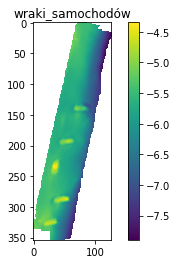

In [47]:
# Wyświetlenie wyniku
plt.figure()
plt.title("wraki_samochodów")
p = plt.imshow(zMeshGrid)
plt.colorbar(p)
plt.show()

In [48]:
# Zapis do pliku CSV
data = {'X': xMeshGrid.flatten(), 'Y': yMeshGrid.flatten(), 'Z': zMeshGrid.flatten()}
df = pd.DataFrame(data)
df.to_csv("wraki_samochodów_outout", header=False, sep=' ', na_rep='NaN')